# Exploración y verificación de compraventas urbanas

Grupo 4 · Entrega 1 · 25 de octubre de 2026

Guillermo Prieto, Juan Sebastián Victoria, Ivette Yvonne Campos y Jecika León.

In [1]:
from pathlib import Path
import json, urllib.request, urllib.parse
import pandas as pd
import matplotlib.pyplot as plt

URL = "https://www.datos.gov.co/resource/7y2j-43cv.json"
FILTRO_BASE = ("divipola in ('63001','17001','66001') "
               "AND nombre_natujur = 'COMPRAVENTA' "
               "AND upper(tipo_predio_zona) = 'URBANO' "
               "AND year_radica between '2015' and '2023'")
CAMPOS = ['pk','municipio','year_radica','valor','tiene_mas_de_un_valor',
          'divipola','nombre_natujur','tipo_predio_zona']
archivo = Path('datos_fuente_auditados.csv')
if archivo.exists():
    universo = pd.read_csv(archivo, dtype={'pk':str,'divipola':str})
    print('Se utiliza el corte incluido con los soportes.')
else:
    registros = []
    for offset in range(0, 1_000_000, 40_000):
        parametros = {'$select':','.join(CAMPOS), '$where':FILTRO_BASE,
                      '$order':'pk', '$limit':40_000, '$offset':offset}
        with urllib.request.urlopen(URL+'?'+urllib.parse.urlencode(parametros), timeout=180) as r:
            pagina = json.load(r)
        registros.extend(pagina)
        if len(pagina) < 40_000:
            break
    else:
        raise RuntimeError('Se alcanzó el límite de seguridad; revisar la descarga.')
    universo = pd.DataFrame(registros, columns=CAMPOS)
    universo.to_csv(archivo, index=False)
    print('Se descargó un corte nuevo; puede diferir del corte entregado.')
for c in ['year_radica','valor','tiene_mas_de_un_valor']:
    universo[c] = pd.to_numeric(universo[c], errors='coerce')
assert universo.pk.notna().all() and universo.pk.is_unique, 'Revisar claves pk.'
assert universo.year_radica.between(2015,2023).all()
assert set(universo.municipio) == {'ARMENIA','MANIZALES','PEREIRA'}
print('Registros del universo:', len(universo))
datos_piloto = universo.loc[universo.valor.gt(0) & universo.tiene_mas_de_un_valor.eq(0)].copy()
print('Registros monetarios:', len(datos_piloto))
Path('figuras').mkdir(exist_ok=True)


Se descargó un corte nuevo; puede diferir del corte entregado.
Registros del universo: 214190
Registros monetarios: 214036


## Cobertura y calidad

Se inspeccionan los ocho campos del corte. La ausencia de claves repetidas no demuestra ausencia de inmuebles con varias operaciones. La tasa de conservación monetaria no es una medida integral de calidad.

In [2]:
calidad = pd.DataFrame({'campo':universo.columns,
                        'nulos':universo.isna().sum().values})
display(calidad)
print('Claves pk repetidas:', universo.pk.duplicated().sum())
print('Filas idénticas en los ocho campos:', universo.duplicated().sum())
print('Valor menor o igual a cero:', universo.valor.le(0).sum())
print('Indicador de múltiples valores distinto de cero:', universo.tiene_mas_de_un_valor.ne(0).sum())
cobertura = universo.groupby('municipio').size().to_frame('universo')
cobertura['conservados'] = datos_piloto.groupby('municipio').size()
cobertura['excluidos'] = cobertura.universo - cobertura.conservados
cobertura['cobertura_pct'] = 100*cobertura.conservados/cobertura.universo
display(cobertura.round(4))
calidad.to_csv('calidad_campos.csv', index=False)
cobertura.to_csv('cobertura_municipios.csv')


,campo,nulos
0,pk,0
1,municipio,0
2,year_radica,0
3,valor,0
4,tiene_mas_de_un_valor,0
5,divipola,0
6,nombre_natujur,0
7,tipo_predio_zona,0


Claves pk repetidas: 0
Filas idénticas en los ocho campos: 0
Valor menor o igual a cero: 144
Indicador de múltiples valores distinto de cero: 10


,universo,conservados,excluidos,cobertura_pct
municipio,,,,
ARMENIA,86565,86560,5,99.9942
MANIZALES,66313,66295,18,99.9729
PEREIRA,61312,61181,131,99.7863


## Actividad y evolución relativa

Se retoman los indicadores de variación interanual e índice con base 2015 = 100 incorporados en el trabajo del equipo. Las variaciones describen registros, sin probar rentabilidad ni valorización de inmuebles equivalentes.

municipio,ARMENIA,MANIZALES,PEREIRA
year_radica,,,
2015,9072,7712,7031
2016,10487,7187,8238
2017,9478,6761,7086
2018,9697,7363,6170
2019,8612,7709,6363
2020,8521,6210,5798
2021,10942,8410,6897
2022,10079,8581,7375
2023,9672,6362,6223


municipio,ARMENIA,MANIZALES,PEREIRA
year_radica,,,
2015,NaN,NaN,NaN
2016,15.60,-6.81,17.17
2017,-9.62,-5.93,-13.98
2018,2.31,8.90,-12.93
2019,-11.19,4.70,3.13
2020,-1.06,-19.44,-8.88
2021,28.41,35.43,18.95
2022,-7.89,2.03,6.93
2023,-4.04,-25.86,-15.62


municipio,ARMENIA,MANIZALES,PEREIRA
year_radica,,,
2015,100.00,100.00,100.00
2016,115.60,93.19,117.17
2017,104.48,87.67,100.78
2018,106.89,95.47,87.75
2019,94.93,99.96,90.50
2020,93.93,80.52,82.46
2021,120.61,109.05,98.09
2022,111.10,111.27,104.89
2023,106.61,82.49,88.51


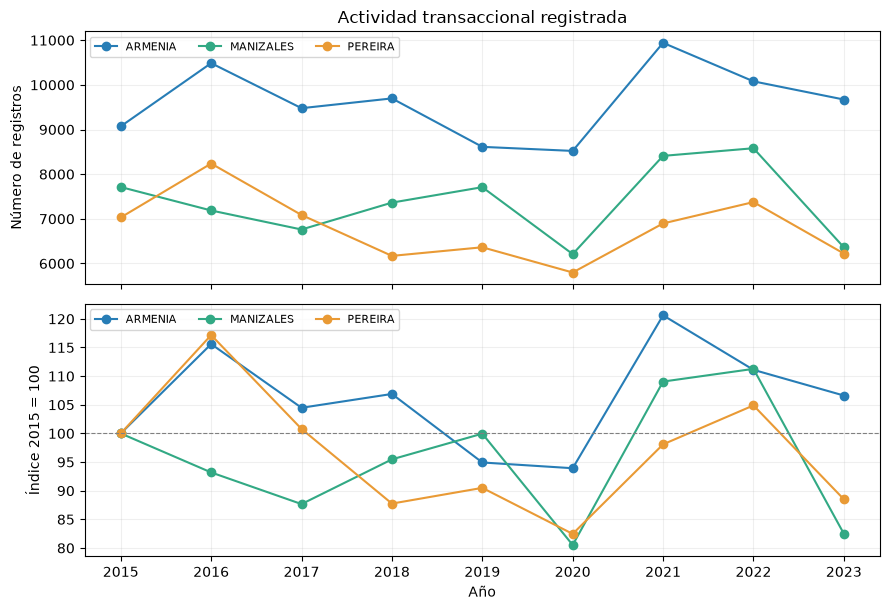

In [3]:
tabla_anual = datos_piloto.groupby(['year_radica','municipio']).size().unstack()
variacion_anual = tabla_anual.pct_change(fill_method=None)*100
indice_base_2015 = tabla_anual.div(tabla_anual.loc[2015],axis='columns')*100
display(tabla_anual)
display(variacion_anual.round(2))
display(indice_base_2015.round(2))
fig, ejes = plt.subplots(2,1,figsize=(9,6.2),sharex=True)
colores = ['#277DB6','#32A984','#E99A35']
tabla_anual.plot(ax=ejes[0],marker='o',color=colores)
ejes[0].set_ylabel('Número de registros')
ejes[0].set_title('Actividad transaccional registrada')
indice_base_2015.plot(ax=ejes[1],marker='o',color=colores)
ejes[1].axhline(100,color='gray',ls='--',lw=.8)
ejes[1].set_ylabel('Índice 2015 = 100');ejes[1].set_xlabel('Año')
for ax in ejes:
    ax.grid(alpha=.2);ax.legend(title=None,ncol=3,fontsize=8)
    ax.set_xticks(tabla_anual.index)
fig.tight_layout();fig.savefig('figuras/actividad.png',dpi=200);plt.show()


## Distribución monetaria y señales de revisión

Se calcula la media directamente sobre los registros, sin promediar medias anuales. Las señales de Tukey se definen fuera de Q1 − 1,5·RIQ y Q3 + 1,5·RIQ por municipio. Se conservan en el conjunto; no se interpretan como errores ni irregularidades. El histograma muestra el rango 10³–10¹² COP en escala logarítmica; los valores inferiores a 1.000 COP están fuera de la ventana visual y permanecen en los cálculos.

,registros,mediana,promedio,minimo,maximo,q1,q3
municipio,,,,,,,
ARMENIA,86560,70000000.0,1.024290e+08,50.00,1.761467e+10,22200000.0,122651000.0
MANIZALES,66295,99000000.0,1.930403e+08,1.00,3.841362e+11,35899000.0,168981552.0
PEREIRA,61181,92500000.0,2.838544e+08,471.56,3.780000e+11,45000000.0,160000000.0


municipio,ARMENIA,MANIZALES,PEREIRA
year_radica,,,
2015,45104500.0,83100000.0,79736000.0
2016,48261848.0,79600000.0,86450000.0
2017,57500000.0,90000000.0,81875000.0
2018,56086000.0,102500000.0,82325000.0
2019,70000000.0,123177128.0,95000000.0
2020,80987400.0,95875000.0,95000000.0
2021,77500000.0,90000000.0,103000000.0
2022,81200000.0,100000000.0,122600000.0
2023,108000000.0,135000000.0,123000000.0


,atipicos_riq,porcentaje,limite_superior
municipio,,,
ARMENIA,5014,5.79,273327500.0
MANIZALES,2873,4.33,368605380.0
PEREIRA,4742,7.75,332500000.0


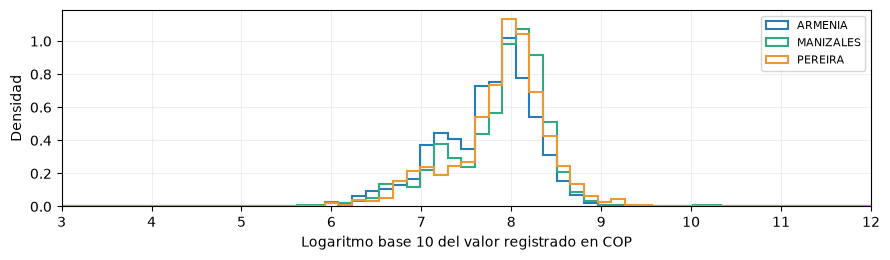

In [4]:
resumen = datos_piloto.groupby('municipio').valor.agg(registros='count',mediana='median',promedio='mean',minimo='min',maximo='max')
resumen['q1'] = datos_piloto.groupby('municipio').valor.quantile(.25)
resumen['q3'] = datos_piloto.groupby('municipio').valor.quantile(.75)
display(resumen.round(2))
resumen.to_csv('resumen_monetario.csv')
tabla_mediana = datos_piloto.groupby(['year_radica','municipio']).valor.median().unstack()
display(tabla_mediana)
filas = []
for municipio, grupo in datos_piloto.groupby('municipio'):
    q1,q3 = grupo.valor.quantile([.25,.75]);riq = q3-q1
    atipicos = (grupo.valor < q1-1.5*riq) | (grupo.valor > q3+1.5*riq)
    filas.append({'municipio':municipio,'atipicos_riq':int(atipicos.sum()),
                  'porcentaje':100*atipicos.mean(), 'limite_superior':q3+1.5*riq})
atipicos = pd.DataFrame(filas).set_index('municipio')
display(atipicos.round(2))
atipicos.to_csv('valores_extremos.csv')
fig, ax = plt.subplots(figsize=(9,2.7))
import numpy as np
for (municipio,grupo),color in zip(datos_piloto.groupby('municipio'),colores):
    ax.hist(np.log10(grupo.valor),bins=np.linspace(0,12,80),density=True,
            histtype='step',linewidth=1.5,label=municipio,color=color)
ax.set_xlabel('Logaritmo base 10 del valor registrado en COP')
ax.set_ylabel('Densidad');ax.set_xlim(3,12);ax.legend(fontsize=8)
ax.grid(alpha=.2);fig.tight_layout()
fig.savefig('figuras/distribucion.png',dpi=200);plt.show()


## Interpretación y conciliación

En 2023, Armenia registra 6,61 % más operaciones que en 2015; Manizales, 17,51 % menos, y Pereira, 11,49 % menos. El nuevo corte confirma una mediana de $70 millones y media de $102,4 millones para Armenia, y media de $193,0 millones para Manizales. Difieren de algunas salidas guardadas del notebook original ($68 millones; $101,6 millones; $210,2 millones). La descarga anterior ordenaba por municipio y año, claves que no definen un orden único para paginar. Se reemplaza ese orden por `pk` y se comprueba su unicidad; no se atribuye la diferencia a una causa única sin recuperar el archivo histórico.

La base solo aporta contexto municipal y temporal para la estimación exploratoria. No incorpora área, estado físico ni características suficientes para un avalúo individual. El modelo supervisado se evaluará con partición temporal y contra una mediana municipal calculada exclusivamente en entrenamiento.

In [6]:
# Pruebas de consistencia del corte entregado. Un corte nuevo requiere actualizar estas referencias.
esperados = {'ARMENIA':86560,'MANIZALES':66295,'PEREIRA':61181}
assert len(universo)==214190 and len(datos_piloto)==214036
assert datos_piloto.groupby('municipio').size().to_dict()==esperados
assert datos_piloto.pk.is_unique
assert datos_piloto[CAMPOS].isna().sum().sum()==0
assert resumen.loc['ARMENIA','mediana']==70_000_000
assert resumen.loc['MANIZALES','mediana']==99_000_000
assert resumen.loc['PEREIRA','mediana']==92_500_000
# Las filas repetidas por municipio, año y valor NO se eliminan: pueden ser operaciones distintas.
datos_piloto.to_csv('datos_monetarios_auditados.csv', index=False)
print('Pruebas del corte entregado: correctas.')


Pruebas del corte entregado: correctas.
